# Book Recommender on a Medallion Data Lake

**Course:** Data Mining Lab — Assignment 2  
**Student:** Piyush Nayak  
**Dataset:** Book-Crossing (`BX-Users`, `BX-Books`, `BX-Book-Ratings`)

This notebook implements a complete book recommender system on a medallion data lake:

```
raw CSV files
    -> Bronze   faithful Parquet copies of the source files
    -> Silver   cleaned, de-duplicated, filtered tables
    -> Gold     sparse user x book matrix + ID mappings + aggregates
    -> Model    item-based collaborative filtering with cosine similarity
```

The recommender answers two questions:

1. **"Which books are similar to this one?"** — `get_similar_books(book_title, n=10)`
2. **"What should this user read next?"** — `recommend(user_id, n=10)`

### Notebook map

| Section | What it contains |
|---|---|
| 0 | Environment setup, configurable working directory, dataset discovery |
| 1 | **Bronze** — raw ingestion with `;` delimiter and latin-1 encoding |
| 2 | **EDA** — shapes, missing values, rating/age/year distributions, sparsity |
| 3 | **Silver** — cleaning, validation, minimum-activity filtering |
| 4 | **Gold** — CSR rating matrix, lookup and aggregate tables |
| 5 | **Item-based CF** — cosine `NearestNeighbors`, both recommender functions |
| 6 | **Demo and sanity checks** — three users, similar-book queries, assertions |
| 7 | Conclusion, limitations and next steps |

### How to run

* **Google Colab (recommended):** `Runtime -> Run all`. If the three CSV files are not already in
  `/content`, the notebook downloads the official archive automatically and extracts it.
* **Locally:** place the `book-crossings/` folder next to the notebook, or point
  `BOOKCROSSING_DATA_DIR` at the folder containing the three CSVs. Set `BOOK_REC_WORKDIR` to change
  where the data lake is written.
* The notebook is idempotent: running it again overwrites the Bronze/Silver/Gold artifacts.
* Generated folders (`raw/`, `bronze/`, `silver/`, `gold/`) are ignored by Git; only this notebook
  and the README are committed.
* Expected runtime on a Colab CPU runtime: roughly 2–3 minutes.

## 0. Environment setup

The notebook only needs the standard data stack (pandas, NumPy, PyArrow, SciPy, scikit-learn,
Matplotlib, Seaborn). Colab ships all of them. The next cell checks for missing packages and installs
only what is absent, so the notebook works in a fresh environment without manual `pip install` steps.

In [1]:
import importlib.util
import subprocess
import sys

REQUIRED_PACKAGES = {
    "pandas": "pandas",
    "numpy": "numpy",
    "pyarrow": "pyarrow",
    "scipy": "scipy",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
}

missing = [package for module, package in REQUIRED_PACKAGES.items()
           if importlib.util.find_spec(module) is None]

if missing:
    print("Installing missing packages:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
%matplotlib inline

import contextlib
import csv
import html
import io
import os
import re
import shutil
import urllib.request
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
from IPython.display import display
from scipy import sparse
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 10})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)

print(f"Python      {sys.version.split()[0]}")
print(f"pandas      {pd.__version__}")
print(f"numpy       {np.__version__}")
print(f"scipy       {scipy.__version__}")
print(f"scikit-learn{sklearn.__version__:>7}")
print(f"matplotlib  {matplotlib.__version__}")
print(f"seaborn     {sns.__version__}")

Python      3.14.6
pandas      3.0.6
numpy       2.5.3
scipy       1.18.1
scikit-learn  1.9.1
matplotlib  3.11.2
seaborn     0.13.2


### 0.1 Working directory and data-lake layout

Everything is written under one configurable root, `WORK_DIR`. The default is the current directory,
which is `/content` in Colab and the notebook's folder locally. The three medallion layers are created
automatically, so the notebook never depends on a hard-coded Windows path.

In [3]:
DATA_URL = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
DATASET_FILES = {
    "users": "BX-Users.csv",
    "books": "BX-Books.csv",
    "ratings": "BX-Book-Ratings.csv",
}

CURRENT_YEAR = datetime.now().year
IN_COLAB = "google.colab" in sys.modules

WORK_DIR = Path(os.environ.get("BOOK_REC_WORKDIR", Path.cwd())).expanduser().resolve()
RAW_DIR = WORK_DIR / "raw"
BRONZE_DIR = WORK_DIR / "bronze"
SILVER_DIR = WORK_DIR / "silver"
GOLD_DIR = WORK_DIR / "gold"

for folder in (RAW_DIR, BRONZE_DIR, SILVER_DIR, GOLD_DIR):
    folder.mkdir(parents=True, exist_ok=True)


def display_path(path):
    # Show paths relative to the current directory so outputs stay environment-neutral.
    try:
        return path.relative_to(Path.cwd())
    except ValueError:
        return path


print("Colab runtime :", IN_COLAB)
print("WORK_DIR      :", display_path(WORK_DIR))
for folder in (RAW_DIR, BRONZE_DIR, SILVER_DIR, GOLD_DIR):
    print(f"  {folder.name:8s} -> {display_path(folder)}")

Colab runtime : False
WORK_DIR      : .
  raw      -> raw
  bronze   -> bronze
  silver   -> silver
  gold     -> gold


### 0.2 Locate the dataset (with an official download fallback)

The notebook looks for the three CSVs in this order:

1. the directory named by the `BOOKCROSSING_DATA_DIR` environment variable,
2. `WORK_DIR` itself, `WORK_DIR/book-crossings`, `WORK_DIR/data` and `WORK_DIR/raw`,
3. the parent directory and `WORK_DIR.parent/book-crossings` (this is how the local workspace is laid out),
4. one to three folder levels below `WORK_DIR`.

If nothing is found, the official freeCodeCamp archive is downloaded into `raw/` and extracted. The CDN
rejects the default `urllib` user agent with HTTP 403, so a browser-like user agent is sent.

In [4]:
def is_dataset_dir(path):
    return path.is_dir() and all((path / name).is_file() for name in DATASET_FILES.values())


def find_local_dataset():
    candidates = []
    env_dir = os.environ.get("BOOKCROSSING_DATA_DIR")
    if env_dir:
        candidates.append(Path(env_dir))
    candidates.extend([
        WORK_DIR,
        WORK_DIR / "book-crossings",
        WORK_DIR / "data",
        WORK_DIR / "raw",
        WORK_DIR.parent,
        WORK_DIR.parent / "book-crossings",
    ])
    for depth in (1, 2, 3):
        candidates.extend(hit.parent for hit in WORK_DIR.glob("*/" * depth + "BX-Users.csv"))
    for candidate in candidates:
        try:
            if is_dataset_dir(candidate):
                return candidate.resolve()
        except OSError:
            continue
    return None


def download_dataset(destination):
    destination.mkdir(parents=True, exist_ok=True)
    archive_path = destination / "book-crossings.zip"
    if not archive_path.exists():
        print("Downloading", DATA_URL)
        request = urllib.request.Request(DATA_URL, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(request, timeout=180) as response, open(archive_path, "wb") as handle:
            shutil.copyfileobj(response, handle)
        print(f"Downloaded {archive_path.stat().st_size / 1e6:.1f} MB")
    with zipfile.ZipFile(archive_path) as archive:
        archive.extractall(destination)
    for hit in destination.glob("**/BX-Users.csv"):
        if is_dataset_dir(hit.parent):
            return hit.parent.resolve()
    raise FileNotFoundError("The downloaded archive does not contain the expected CSV files.")


DATA_DIR = find_local_dataset()
if DATA_DIR is None:
    print("No local Book-Crossing CSVs found — using the official download fallback.")
    DATA_DIR = download_dataset(RAW_DIR)

print("\nDATA_DIR:", display_path(DATA_DIR))
for name in DATASET_FILES.values():
    path = DATA_DIR / name
    print(f"  {name:22s} {path.stat().st_size / 1e6:8.2f} MB")


DATA_DIR: book-crossings
  BX-Users.csv              12.28 MB
  BX-Books.csv              77.79 MB
  BX-Book-Ratings.csv       30.68 MB


## 1. Bronze layer — faithful ingestion

Bronze is the "landing zone": it should preserve the source data as closely as possible and add only
audit metadata. No cleaning, filtering or type coercion happens here.

Three ingestion details matter for this dataset:

* **Delimiter:** the files are semicolon-separated, not comma-separated.
* **Encoding:** the files are ISO-8859-1 (latin-1), not UTF-8. latin-1 maps every byte, so reading with
  it never fails and no rows are lost.
* **Escaped quotes:** some book titles contain `\"`. Without `escapechar="\\"`, pandas raises a tokenizing error (or, with
  `on_bad_lines="skip"`, loses 19 book rows); with it, all 271,379 rows load.

Each table gets an `ingestion_timestamp` column (a single UTC timestamp for the run) and is written to
`bronze/<table>.parquet` with PyArrow. Nothing else is changed.

In [5]:
CSV_READ_OPTIONS = dict(sep=";", encoding="latin-1", escapechar="\\", low_memory=False)
ingestion_timestamp = pd.Timestamp(datetime.now(timezone.utc))

for table, filename in DATASET_FILES.items():
    frame = pd.read_csv(DATA_DIR / filename, **CSV_READ_OPTIONS)
    frame["ingestion_timestamp"] = ingestion_timestamp
    frame.to_parquet(BRONZE_DIR / f"{table}.parquet", index=False, engine="pyarrow")
    print(f"{table:8s} {frame.shape[0]:>9,} rows x {frame.shape[1]:>2} cols  ->  bronze/{table}.parquet")

print("\ningestion_timestamp:", ingestion_timestamp)

users      278,858 rows x  4 cols  ->  bronze/users.parquet


books      271,379 rows x  9 cols  ->  bronze/books.parquet


ratings  1,149,780 rows x  4 cols  ->  bronze/ratings.parquet

ingestion_timestamp: 2026-11-26 15:34:51.277588+00:00


### 1.1 Verify that Bronze lost nothing

A simple line count is not reliable here because one user location contains a quoted line break.
`csv.reader` understands quoted newlines, so it gives the true number of records. Bronze rows must
match that count exactly for all three tables.

In [6]:
def count_source_records(path):
    with open(path, encoding="latin-1", newline="") as handle:
        reader = csv.reader(handle, delimiter=";", escapechar="\\")
        return sum(1 for _ in reader) - 1


verification = []
for table, filename in DATASET_FILES.items():
    source_records = count_source_records(DATA_DIR / filename)
    bronze_rows = len(pd.read_parquet(BRONZE_DIR / f"{table}.parquet"))
    verification.append({
        "table": table,
        "csv_records": source_records,
        "bronze_rows": bronze_rows,
        "match": source_records == bronze_rows,
    })

verification_df = pd.DataFrame(verification)
display(verification_df)
assert verification_df["match"].all(), "Bronze row counts do not match the source files."
print("Bronze row counts match the source record counts exactly.")

for table in DATASET_FILES:
    frame = pd.read_parquet(BRONZE_DIR / f"{table}.parquet")
    print(f"\n{table} columns: {list(frame.columns)}")

,table,csv_records,bronze_rows,match
0,users,278858,278858,True
1,books,271379,271379,True
2,ratings,1149780,1149780,True


Bronze row counts match the source record counts exactly.

users columns: ['User-ID', 'Location', 'Age', 'ingestion_timestamp']

books columns: ['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher', 'Image-URL-S', 'Image-URL-M', 'Image-URL-L', 'ingestion_timestamp']

ratings columns: ['User-ID', 'ISBN', 'Book-Rating', 'ingestion_timestamp']


**Bronze interpretation.** All 278,858 user records, 271,379 book records and 1,149,780 rating records
are present, and the only added column is `ingestion_timestamp`. The Bronze layer is therefore a
complete, replayable copy of the source and every later number can be traced back to it.

## 2. Exploratory data analysis

All EDA is performed on the Bronze Parquet files, so it describes exactly what was ingested. Every
subsection ends with the concrete cleaning action that follows from it in the Silver layer.

### 2.1 Shapes, data types and missing values

In [7]:
users_bronze = pd.read_parquet(BRONZE_DIR / "users.parquet")
books_bronze = pd.read_parquet(BRONZE_DIR / "books.parquet")
ratings_bronze = pd.read_parquet(BRONZE_DIR / "ratings.parquet")


def column_profile(frame):
    return pd.DataFrame({
        "dtype": frame.dtypes.astype(str).to_numpy(),
        "non_null": frame.notna().sum().to_numpy(),
        "missing": frame.isna().sum().to_numpy(),
        "missing_%": (frame.isna().mean().to_numpy() * 100).round(2),
        "unique": frame.nunique(dropna=True).to_numpy(),
    }, index=frame.columns)


for name, frame in [("users", users_bronze), ("books", books_bronze), ("ratings", ratings_bronze)]:
    print(f"\n{name.upper()} — shape {frame.shape[0]:,} x {frame.shape[1]}")
    display(column_profile(frame))


USERS — shape 278,858 x 4


,dtype,non_null,missing,missing_%,unique
User-ID,int64,278858,0,0.00,278858
Location,str,278858,0,0.00,57339
Age,float64,168096,110762,39.72,165
ingestion_timestamp,"datetime64[us, UTC]",278858,0,0.00,1



BOOKS — shape 271,379 x 9


,dtype,non_null,missing,missing_%,unique
ISBN,str,271379,0,0.0,271379
Book-Title,str,271379,0,0.0,242154
Book-Author,str,271377,2,0.0,102026
Year-Of-Publication,int64,271379,0,0.0,116
Publisher,str,271377,2,0.0,16806
Image-URL-S,str,271379,0,0.0,271063
Image-URL-M,str,271379,0,0.0,271063
Image-URL-L,str,271379,0,0.0,271063
ingestion_timestamp,"datetime64[us, UTC]",271379,0,0.0,1



RATINGS — shape 1,149,780 x 4


,dtype,non_null,missing,missing_%,unique
User-ID,int64,1149780,0,0.0,105283
ISBN,str,1149780,0,0.0,340556
Book-Rating,int64,1149780,0,0.0,11
ingestion_timestamp,"datetime64[us, UTC]",1149780,0,0.0,1


**What this reveals.** Bronze contains **278,858 users**, **271,379 books** and **1,149,780 ratings**.
`age` is missing for **110,762 users (39.7%)** — by far the largest gap. `Book-Author` and `Publisher`
are missing only twice each, and the ratings table is complete. ISBN and the other identifiers arrive
as text (`str`), while `Age` is `float64` (because of NaNs) and `Book-Rating` / `Year-Of-Publication`
are `int64`.

**Issues identified.** A 40% missing age column cannot be dropped without losing two-fifths of the
users, and the remaining ages contain impossible values (see 2.4). The two missing book fields are
cosmetic but would produce blank labels in recommendations.

**Silver action.** Coerce `age` numerically, replace impossible ages with nulls, and impute the median.
Fill missing author/publisher with explicit "Unknown Author" / "Unknown Publisher" labels. Nothing is
dropped at this stage because of missingness alone.

### 2.2 Duplicates, referential integrity and text quality

In [8]:
users_raw = users_bronze.drop(columns="ingestion_timestamp")
books_raw = books_bronze.drop(columns="ingestion_timestamp")
ratings_raw = ratings_bronze.drop(columns="ingestion_timestamp")

normalised_isbn = books_raw["ISBN"].astype("string").str.strip().str.upper()

quality = pd.DataFrame([
    {"check": "users: exact duplicate rows", "count": int(users_raw.duplicated().sum())},
    {"check": "users: duplicate User-ID", "count": int(users_raw["User-ID"].duplicated().sum())},
    {"check": "books: exact duplicate rows", "count": int(books_raw.duplicated().sum())},
    {"check": "books: duplicate ISBN (raw)", "count": int(books_raw["ISBN"].duplicated().sum())},
    {"check": "books: duplicate ISBN (normalised)", "count": int(normalised_isbn.duplicated().sum())},
    {"check": "ratings: exact duplicate rows", "count": int(ratings_raw.duplicated().sum())},
    {"check": "ratings: duplicate (User-ID, ISBN)", "count": int(ratings_raw.duplicated(["User-ID", "ISBN"]).sum())},
    {"check": "ratings with unknown ISBN", "count": int((~ratings_raw["ISBN"].isin(books_raw["ISBN"])).sum())},
    {"check": "ratings with unknown User-ID", "count": int((~ratings_raw["User-ID"].isin(users_raw["User-ID"])).sum())},
    {"check": "book titles with HTML entities", "count": int(books_raw["Book-Title"].str.contains(r"&\w+;", na=False).sum())},
    {"check": "book titles with mojibake", "count": int(books_raw["Book-Title"].str.contains("Ã|Â", na=False).sum())},
])
display(quality)

,check,count
0,users: exact duplicate rows,0
1,users: duplicate User-ID,0
2,books: exact duplicate rows,0
3,books: duplicate ISBN (raw),0
4,books: duplicate ISBN (normalised),315
5,ratings: exact duplicate rows,0
6,"ratings: duplicate (User-ID, ISBN)",0
7,ratings with unknown ISBN,118605
8,ratings with unknown User-ID,0
9,book titles with HTML entities,4908


**What this reveals.** There are **no exact duplicate rows**, but normalising ISBN to upper case exposes
**315 duplicate books** — mostly a lower-case `x` check digit (`000225669x` vs `000225669X`) plus one
whitespace variant. **118,605 ratings (10.3%)** point at an ISBN that does not exist in `BX-Books`;
no rating points at an unknown user. Text quality is also imperfect: **4,908 titles contain HTML
entities** such as `&amp;`, and **6,634 titles contain mojibake** (`Ã©` instead of `é`).

**Issues identified.** Duplicate ISBNs would create duplicate rows in the Gold matrix, orphan ratings
cannot be joined to any book, and unescaped/mojibake text produces ugly or duplicated titles.

**Silver action.** Normalise ISBN (strip + upper case) before de-duplicating, drop ratings whose ISBN or
user is unknown, unescape HTML entities, repair latin-1 mojibake where possible, and collapse
whitespace.

### 2.3 Rating distribution (explicit vs implicit)

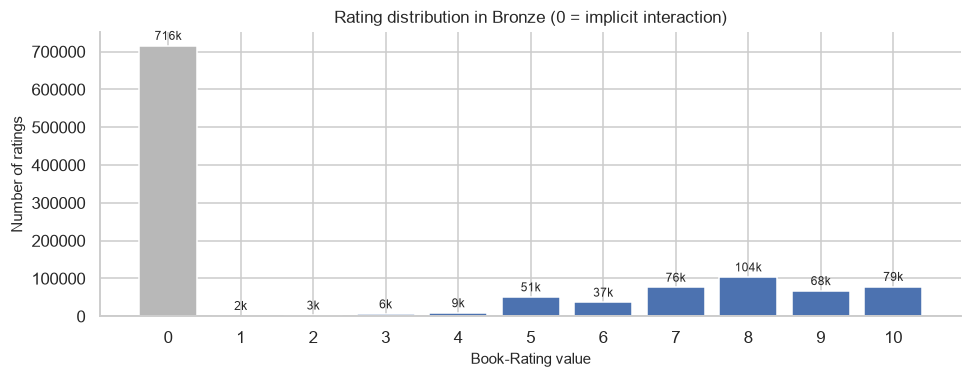

zero ratings        : 716,109 / 1,149,780 (62.28%)
explicit ratings 1-10: 433,671

explicit counts:
Book-Rating
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610


In [9]:
rating_counts = ratings_bronze["Book-Rating"].value_counts().sort_index()
zero_ratings = int(rating_counts.get(0, 0))
explicit_ratings = len(ratings_bronze) - zero_ratings

fig, ax = plt.subplots(figsize=(9, 3.6))
colours = ["#b8b8b8"] + ["#4c72b0"] * 10
bars = ax.bar(rating_counts.index, rating_counts.values, color=colours)
ax.bar_label(bars, labels=[f"{value / 1000:.0f}k" for value in rating_counts.values], fontsize=8, padding=2)
ax.set_xticks(range(0, 11))
ax.set_xlabel("Book-Rating value")
ax.set_ylabel("Number of ratings")
ax.set_title("Rating distribution in Bronze (0 = implicit interaction)")
sns.despine()
plt.tight_layout()
plt.show()

print(f"zero ratings        : {zero_ratings:,} / {len(ratings_bronze):,} ({zero_ratings / len(ratings_bronze):.2%})")
print(f"explicit ratings 1-10: {explicit_ratings:,}")
print("\nexplicit counts:")
print(rating_counts.loc[1:].to_string())

**What this reveals.** **716,109 of 1,149,780 ratings (62.28%) are zero.** In Book-Crossing a zero means
an implicit interaction (the user shelved or owned the book); it does not express a preference and has
no direction. The 433,671 explicit ratings are strongly skewed towards the top of the scale: **8 is the
mode with 103,736 ratings**, and 9–10 together account for 146,151 ratings, while 1–4 total only 19,429.

**Issues identified.** Keeping zeros would treat "owned but unrated" as the lowest possible score and
would dominate the matrix (62% of all values).

**Silver action.** Drop zero ratings and retain only 1–10. This is also the range the assignment
requires.

### 2.4 User age distribution and impossible values

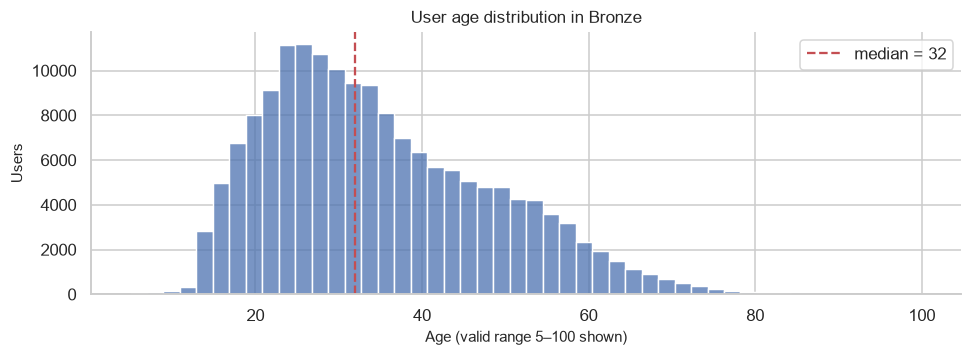

missing : 110,762 (39.7%)
below 5 : 882
above 100: 366
observed range: 0 – 244 | median: 32


In [10]:
age = users_bronze["Age"]
valid_age = age[(age >= 5) & (age <= 100)]

fig, ax = plt.subplots(figsize=(9, 3.4))
sns.histplot(valid_age, bins=48, ax=ax, color="#4c72b0")
ax.axvline(valid_age.median(), color="#c44e52", linestyle="--", label=f"median = {valid_age.median():.0f}")
ax.set_xlabel("Age (valid range 5–100 shown)")
ax.set_ylabel("Users")
ax.set_title("User age distribution in Bronze")
ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

print(f"missing : {age.isna().sum():,} ({age.isna().mean():.1%})")
print(f"below 5 : {(age < 5).sum():,}")
print(f"above 100: {(age > 100).sum():,}")
print(f"observed range: {age.min():.0f} – {age.max():.0f} | median: {age.median():.0f}")

**What this reveals.** The observed age range is **0–244** with a median of **32**. **882 users are
younger than 5** and **366 are older than 100**, both impossible for a book-rating platform. The bulk of
the distribution sits between roughly 15 and 60.

**Issues identified.** Impossible ages would distort any age-based analysis or feature, and 39.7% of
values are missing.

**Silver action.** Set ages below 5 or above 100 to null, then fill all nulls with the median of the
valid ages (32). Median imputation is robust to the remaining skew and keeps every user.

### 2.5 Publication year distribution and invalid years

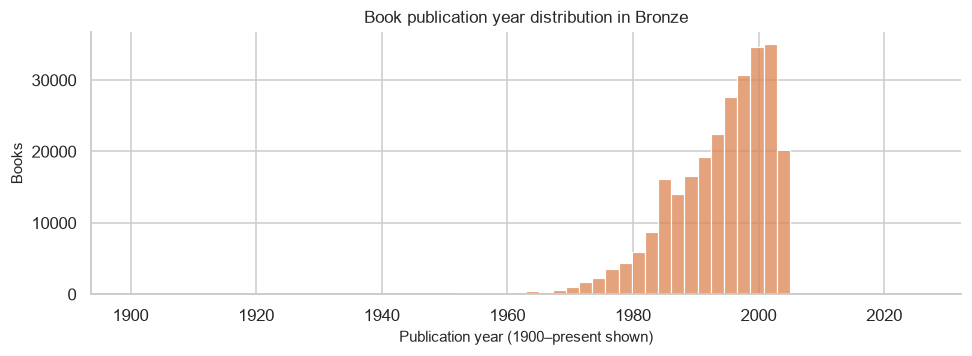

year == 0        : 4,619
year > 2026       : 11 -> [2030, 2037, 2038, 2050]
observed range   : 0 – 2050
years below 1500 : [1376, 1378]


In [11]:
publication_year = pd.to_numeric(books_bronze["Year-Of-Publication"], errors="coerce")
future_years = sorted(int(year) for year in publication_year[publication_year > CURRENT_YEAR].dropna().unique())
early_years = sorted(int(year) for year in publication_year[
    (publication_year > 0) & (publication_year < 1500)].dropna().unique())

fig, ax = plt.subplots(figsize=(9, 3.4))
sns.histplot(publication_year[(publication_year >= 1900) & (publication_year <= CURRENT_YEAR)],
             bins=60, ax=ax, color="#dd8452")
ax.set_xlabel("Publication year (1900–present shown)")
ax.set_ylabel("Books")
ax.set_title("Book publication year distribution in Bronze")
sns.despine()
plt.tight_layout()
plt.show()

print(f"year == 0        : {(publication_year == 0).sum():,}")
print(f"year > {CURRENT_YEAR}       : {(publication_year > CURRENT_YEAR).sum()} -> {future_years}")
print(f"observed range   : {publication_year.min():.0f} – {publication_year.max():.0f}")
print(f"years below 1500 : {early_years}")

**What this reveals.** Publication years span **0–2050**. **4,619 books have year 0** (unknown) and
**11 are in the future** (2030, 2037, 2038, 2050). The distribution peaks in the 1990s–2000s, which fits
a dataset collected around 2004. Two titles are dated **1376 and 1378**; these are Iranian editions that
use the Persian calendar (ISBN prefix 964), so they are legitimate values and are kept.

**Issues identified.** Year 0 and future years are not real publication dates and would break any
time-based feature.

**Silver action.** Set year 0 and any year greater than the current year to null, and store the column as
pandas' nullable `Int64` so missing years stay whole numbers instead of becoming floats.

### 2.6 Ratings per user and per book (long tail)

,entity,count,median_ratings,mean_ratings,max_ratings,share_with_1_rating,entities_with_10_plus
0,users,77805,1,5.57,8524,58.3%,7334
1,books,185973,1,2.33,707,69.7%,5645


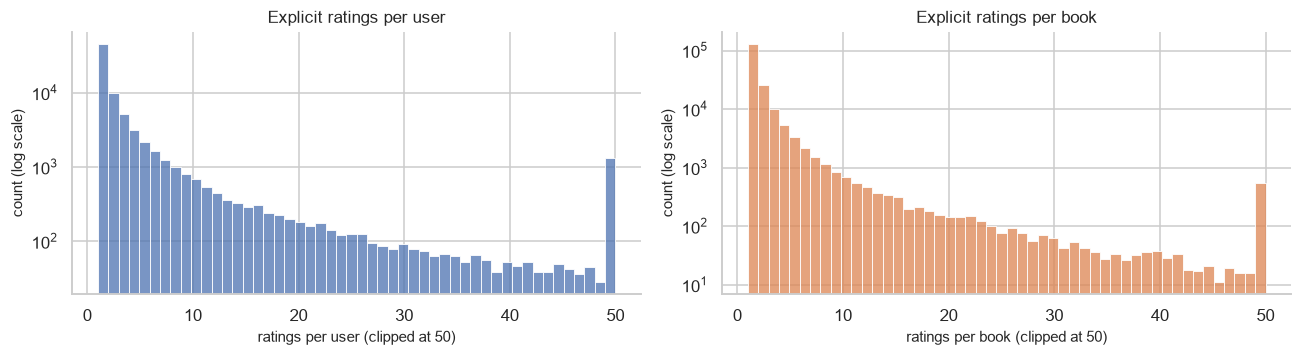

In [12]:
explicit_bronze = ratings_bronze[ratings_bronze["Book-Rating"].between(1, 10)]
per_user = explicit_bronze.groupby("User-ID").size()
per_book = explicit_bronze.groupby("ISBN").size()


def activity_summary(counts, label):
    return {
        "entity": label,
        "count": int(len(counts)),
        "median_ratings": int(counts.median()),
        "mean_ratings": round(float(counts.mean()), 2),
        "max_ratings": int(counts.max()),
        "share_with_1_rating": f"{(counts == 1).mean():.1%}",
        "entities_with_10_plus": int((counts >= 10).sum()),
    }


display(pd.DataFrame([activity_summary(per_user, "users"), activity_summary(per_book, "books")]))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, counts, label, colour in [
    (axes[0], per_user, "ratings per user", "#4c72b0"),
    (axes[1], per_book, "ratings per book", "#dd8452"),
]:
    sns.histplot(counts.clip(upper=50), bins=50, ax=ax, color=colour)
    ax.set_yscale("log")
    ax.set_xlabel(f"{label} (clipped at 50)")
    ax.set_ylabel("count (log scale)")
    ax.set_title(f"Explicit {label}")
sns.despine()
plt.tight_layout()
plt.show()

**What this reveals.** The activity distribution is extremely long-tailed. Among explicit ratings, the
**median user has 1 rating** and **58.3% of users rated exactly one book**. Books are even sparser: the
**median book has 1 rating** and **69.7% of books were rated once**. Only **7,334 users** and
**5,645 books** reach 10 ratings.

**Issues identified.** Item-based cosine similarity is computed from the users two books share. A book
with one rating has no co-rating overlap, so its similarity vector is noise; a user with one rating
cannot support a personalised profile.

**Silver action.** Apply an iterative minimum-activity filter (at least 10 ratings per user and per
book), repeating until both constraints hold simultaneously. The exact threshold is justified with a
comparison table in section 3.4.

### 2.7 User–book matrix sparsity

all ratings            users=105,283  books=340,556  possible pairs= 35,854,757,348  density=0.0032%  sparsity=99.9968%
explicit ratings 1-10  users= 77,805  books=185,973  possible pairs= 14,469,629,265  density=0.0030%  sparsity=99.9970%
top 10% of users account for 69.1% of explicit ratings
top 10% of books account for 49.7% of explicit ratings


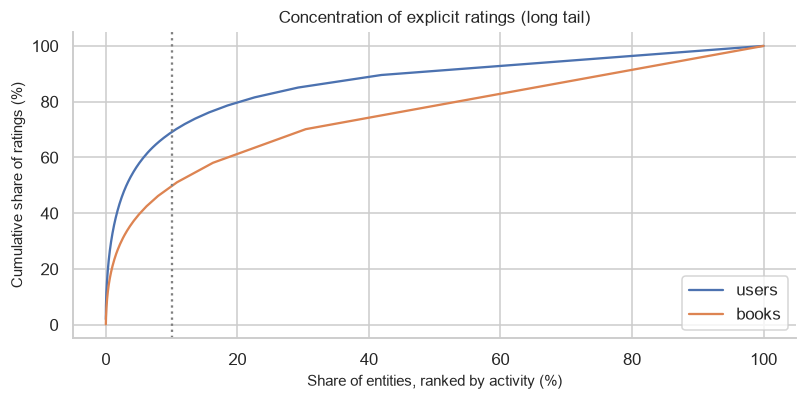

In [13]:
def report_sparsity(frame, label):
    n_users = frame["User-ID"].nunique()
    n_books = frame["ISBN"].nunique()
    possible_pairs = n_users * n_books
    density = len(frame) / possible_pairs
    print(f"{label:22s} users={n_users:>7,}  books={n_books:>7,}  "
          f"possible pairs={possible_pairs:>15,}  density={density:.4%}  sparsity={1 - density:.4%}")
    return possible_pairs


report_sparsity(ratings_bronze, "all ratings")
report_sparsity(explicit_bronze, "explicit ratings 1-10")


def cumulative_share(counts):
    ordered = np.sort(counts.to_numpy())[::-1]
    share_of_entities = np.arange(1, len(ordered) + 1) / len(ordered)
    return share_of_entities, np.cumsum(ordered) / ordered.sum()


fig, ax = plt.subplots(figsize=(7.5, 3.8))
for counts, label, colour in [(per_user, "users", "#4c72b0"), (per_book, "books", "#dd8452")]:
    x, y = cumulative_share(counts)
    ax.plot(x * 100, y * 100, label=label, color=colour)
    print(f"top 10% of {label:5s} account for {np.interp(10, x * 100, y * 100):.1f}% of explicit ratings")
ax.axvline(10, linestyle=":", color="grey")
ax.set_xlabel("Share of entities, ranked by activity (%)")
ax.set_ylabel("Cumulative share of ratings (%)")
ax.set_title("Concentration of explicit ratings (long tail)")
ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

**What this reveals.** With 77,805 users and 185,973 books that have at least one explicit rating, there
are about **14.47 billion possible user–book pairs**, of which only **433,671 are filled**. The matrix is
therefore **99.9970% empty** (99.9968% if zeros are counted). The cumulative curve shows the mirror image
of the long tail: a small share of heavy users and popular books accounts for most interactions.

**Issues identified.** A dense matrix of this size would need about 58 GB and is impossible to work with;
plain cosine on such sparse data is also dominated by the few overlapping users.

**Gold action.** Store the matrix as a SciPy CSR sparse matrix (a few hundred kilobytes after filtering)
and never materialise it densely. The Silver activity filter raises density to a workable level.

### 2.8 EDA summary → Silver actions

| Finding | Value | Silver action |
|---|---|---|
| Zero ratings | 716,109 (62.28%) | drop, keep 1–10 |
| Missing age | 110,762 (39.7%) | median imputation (32) |
| Impossible age | 882 under 5, 366 over 100 | null, then impute |
| Invalid year | 4,619 zeros, 11 future | set to null |
| Duplicate books | 315 after ISBN normalisation | normalise ISBN, keep first |
| Orphan ratings | 118,605 (10.3%) | drop |
| Text issues | 4,908 HTML entities, 6,634 mojibake titles | unescape, repair, strip |
| Single-rating users | 58.3% | iterative ≥10 filter |
| Single-rating books | 69.7% | iterative ≥10 filter |
| Matrix sparsity | 99.9970% | CSR sparse matrix in Gold |

## 3. Silver layer — cleaning and transformation

Silver is built entirely from Bronze. The rules follow directly from the EDA above, and every important
decision is logged so the row counts can be audited.

The plan:

1. Rename columns to `snake_case` and drop ingestion metadata (it belongs to Bronze).
2. Clean text: unescape HTML entities, repair latin-1 mojibake, collapse whitespace, standardise case.
3. Users: de-duplicate, fix ages, split `location` into city/state/country.
4. Books: drop image URLs, normalise and de-duplicate ISBNs, clean title/author/publisher, fix years.
5. Ratings: de-duplicate, keep 1–10, enforce referential integrity.
6. Apply the iterative minimum-activity filter and keep only users/books that survive it.

### 3.1 Reusable cleaning helpers

`clean_text` performs the same safe operations on every text column. Case is chosen per column type:
ISBNs are upper-cased (so `x` and `X` check digits match), titles/authors/publishers use title case with
apostrophes and ordinals repaired (`Sorcerer's`, `1st`), and location fields are lower-cased for
grouping. `normalise_isbn` additionally removes stray quote characters that a few source fields picked up
from the escaped-quote quirk, and `split_location` strips them from location parts before the
placeholder check.

In [14]:
PLACEHOLDER_VALUES = {
    "", "n/a", "na", "n.a.", "none", "null", "unknown", "?", "-", ".", ",", "x", "xxx", "not available",
}


def repair_mojibake(value):
    # Repair UTF-8 text that was decoded as latin-1, e.g. "ExupÃ©ry" -> "Exupéry".
    if not isinstance(value, str) or ("Ã" not in value and "Â" not in value):
        return value
    try:
        return value.encode("latin-1").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        return value


def clean_text(series, case="lower"):
    series = series.astype("string").map(
        lambda value: repair_mojibake(html.unescape(value)) if isinstance(value, str) else value
    )
    series = series.str.replace(r"\s+", " ", regex=True).str.strip()
    series = series.replace("", pd.NA)
    if case == "upper":
        return series.str.upper()
    if case == "title":
        series = series.str.title()
        series = series.str.replace(r"'([A-Z])\b", lambda match: "'" + match.group(1).lower(), regex=True)
        series = series.str.replace(
            r"\b(\d+)(St|Nd|Rd|Th)\b",
            lambda match: match.group(1) + match.group(2).lower(),
            regex=True,
        )
        return series
    return series.str.lower()


def normalise_isbn(series):
    # Upper-case and drop stray quote characters left by the source's escaped-quote quirk.
    return clean_text(series, case="upper").str.strip('"')


def split_location(location):
    # "city, state, country" -> three fields; 2 parts are read as city + country.
    if not isinstance(location, str):
        return {"city": None, "state": None, "country": None}
    parts = [part.strip().strip('"').strip() for part in location.split(",")]
    parts = [part for part in parts if part and part not in PLACEHOLDER_VALUES]
    if not parts:
        return {"city": None, "state": None, "country": None}
    if len(parts) == 1:
        return {"city": parts[0], "state": None, "country": None}
    if len(parts) == 2:
        return {"city": parts[0], "state": None, "country": parts[1]}
    return {"city": parts[0], "state": ", ".join(parts[1:-1]), "country": parts[-1]}


cleaning_log = []


def log_rows(step, table, n_rows):
    cleaning_log.append({"step": step, "table": table, "rows_after": int(n_rows)})

### 3.2 Users

* De-duplicate exact rows and then `user_id` (the EDA found none, but the rule is applied defensively).
* Coerce `age` to numeric, null out ages outside 5–100, and impute the median of the valid ages.
* Lower-case `location`, split it into `city`, `state`, `country`, and treat placeholders as null.
* Drop the raw `location` column after the split.

In [15]:
users = (users_bronze
         .drop(columns="ingestion_timestamp")
         .rename(columns={"User-ID": "user_id", "Location": "location", "Age": "age"})
         .copy())
log_rows("start", "users", len(users))

before = len(users)
users = users.drop_duplicates().drop_duplicates(subset="user_id", keep="first")
print(f"users: removed {before - len(users):,} duplicate rows")
log_rows("de-duplicate", "users", len(users))

users["age"] = pd.to_numeric(users["age"], errors="coerce")
invalid_age = (users["age"] < 5) | (users["age"] > 100)
print(f"users: ages outside 5-100 set to null: {int(invalid_age.sum()):,}")
users.loc[invalid_age, "age"] = np.nan

median_age = users["age"].median()
users["age"] = users["age"].fillna(median_age).round().astype("int16")
print(f"users: missing ages filled with median = {median_age:.0f}")
log_rows("fix age", "users", len(users))

users["location"] = clean_text(users["location"], case="lower")
location_parts = pd.DataFrame.from_records(
    users["location"].map(split_location).tolist(), index=users.index
)
users = pd.concat([users.drop(columns="location"), location_parts], axis=1)
print("users: location split into city / state / country")
print("missing after split:", users[["city", "state", "country"]].isna().sum().to_dict())
log_rows("split location", "users", len(users))

display(users.head())

users: removed 0 duplicate rows
users: ages outside 5-100 set to null: 1,248
users: missing ages filled with median = 32


users: location split into city / state / country
missing after split: {'city': 87, 'state': 18878, 'country': 3363}


,user_id,age,city,state,country
0,1,32,nyc,new york,usa
1,2,18,stockton,california,usa
2,3,32,moscow,yukon territory,russia
3,4,17,porto,v.n.gaia,portugal
4,5,32,farnborough,hants,united kingdom


### 3.3 Books

* Drop the three `Image-URL-*` columns: they are not needed for recommendations and are large.
* Strip and upper-case ISBN, then keep the first row per ISBN (removes the 315 case/whitespace duplicates).
* Clean title, author and publisher; missing author/publisher become explicit "Unknown ..." labels.
* Null out year 0 and future years and store the result as nullable `Int64`.

In [16]:
books = (books_bronze
         .drop(columns="ingestion_timestamp")
         .rename(columns={
             "ISBN": "isbn",
             "Book-Title": "title",
             "Book-Author": "author",
             "Year-Of-Publication": "year",
             "Publisher": "publisher",
             "Image-URL-S": "image_url_s",
             "Image-URL-M": "image_url_m",
             "Image-URL-L": "image_url_l",
         })
         .drop(columns=["image_url_s", "image_url_m", "image_url_l"])
         .copy())
log_rows("start", "books", len(books))

before = len(books)
books = books.drop_duplicates()
books["isbn"] = normalise_isbn(books["isbn"])
books = books.drop_duplicates(subset="isbn", keep="first")
print(f"books: removed {before - len(books):,} duplicate rows (exact + normalised ISBN)")
log_rows("de-duplicate", "books", len(books))

books["title"] = clean_text(books["title"], case="title")
books["author"] = clean_text(books["author"], case="title").fillna("Unknown Author")
books["publisher"] = clean_text(books["publisher"], case="title").fillna("Unknown Publisher")

books["year"] = pd.to_numeric(books["year"], errors="coerce").astype("Int64")
bad_year = (books["year"] == 0) | (books["year"] > CURRENT_YEAR)
print(f"books: invalid years set to null: {int(bad_year.sum()):,} "
      f"(zero: {int((books['year'] == 0).sum()):,}, future: {int((books['year'] > CURRENT_YEAR).sum())})")
books.loc[bad_year, "year"] = pd.NA
print(f"books: valid year range {books['year'].min()} - {books['year'].max()}")
log_rows("fix year", "books", len(books))

print("books: missing titles:", int(books["title"].isna().sum()))
display(books.head())

books: removed 315 duplicate rows (exact + normalised ISBN)


books: invalid years set to null: 4,623 (zero: 4,612, future: 11)
books: valid year range 1376 - 2026
books: missing titles: 0


,isbn,title,author,year,publisher
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press
1,0002005018,Clara Callan,Richard Bruce Wright,2001,Harperflamingo Canada
2,0060973129,Decision In Normandy,Carlo D'Este,1991,Harperperennial
3,0374157065,Flu: The Story Of The Great Influenza Pandemic Of 1918 And The Sea...,Gina Bari Kolata,1999,Farrar Straus Giroux
4,0393045218,The Mummies Of Urumchi,E. J. W. Barber,1999,W. W. Norton & Company


### 3.4 Ratings

* De-duplicate exact rows, then keep one rating per `(user_id, isbn)` pair.
* Keep only ratings between 1 and 10 (this removes all 716,109 zeros).
* Normalise ISBN and keep only ratings whose user and book exist in the cleaned tables.

The order matters: the pair de-duplication happens after the 1–10 filter, so if a user had both a zero
and an explicit rating for the same book, the explicit rating wins.

In [17]:
ratings = (ratings_bronze
           .drop(columns="ingestion_timestamp")
           .rename(columns={"User-ID": "user_id", "ISBN": "isbn", "Book-Rating": "rating"})
           .copy())
log_rows("start", "ratings", len(ratings))

before = len(ratings)
ratings = ratings.drop_duplicates()
print(f"ratings: removed {before - len(ratings):,} exact duplicate rows")

ratings["rating"] = pd.to_numeric(ratings["rating"], errors="coerce")
before = len(ratings)
ratings = ratings[ratings["rating"].between(1, 10)].copy()
ratings["rating"] = ratings["rating"].astype("int8")
ratings["isbn"] = normalise_isbn(ratings["isbn"])
print(f"ratings: removed {before - len(ratings):,} rows outside 1-10, {len(ratings):,} explicit ratings remain")
log_rows("keep 1-10", "ratings", len(ratings))

before = len(ratings)
ratings = ratings.drop_duplicates(subset=["user_id", "isbn"], keep="last")
print(f"ratings: removed {before - len(ratings):,} duplicate (user, book) pairs")

before = len(ratings)
ratings = ratings[ratings["isbn"].isin(books["isbn"]) & ratings["user_id"].isin(users["user_id"])].copy()
print(f"ratings: removed {before - len(ratings):,} ratings with unknown book or user, {len(ratings):,} remain")
print(f"  users with >=1 rating: {ratings['user_id'].nunique():,} | books with >=1 rating: {ratings['isbn'].nunique():,}")
log_rows("referential integrity", "ratings", len(ratings))

ratings: removed 0 exact duplicate rows


ratings: removed 716,109 rows outside 1-10, 433,671 explicit ratings remain
ratings: removed 1 duplicate (user, book) pairs


ratings: removed 49,816 ratings with unknown book or user, 383,854 remain
  users with >=1 rating: 68,093 | books with >=1 rating: 149,723


### 3.5 Minimum-activity threshold

The filter must be **iterative**: removing inactive users can push a book below the threshold, and
removing that book can push another user below it. A single pass is therefore not enough.

The table compares candidate thresholds on the cleaned ratings. The first row (1/1) is the baseline
before any activity filtering.

In [18]:
def filter_by_activity(frame, min_user_ratings, min_book_ratings):
    # Repeat both filters until the table stops shrinking, so both constraints hold at once.
    while True:
        n_before = len(frame)
        frame = frame[frame.groupby("user_id")["isbn"].transform("size") >= min_user_ratings]
        frame = frame[frame.groupby("isbn")["user_id"].transform("size") >= min_book_ratings]
        if len(frame) == n_before:
            return frame


threshold_rows = []
for min_user, min_book in [(1, 1), (5, 5), (8, 8), (10, 10), (10, 15), (12, 12), (15, 15)]:
    filtered = filter_by_activity(ratings, min_user, min_book)
    n_users = filtered["user_id"].nunique()
    n_books = filtered["isbn"].nunique()
    density = len(filtered) / (n_users * n_books) if n_users and n_books else 0.0
    threshold_rows.append({
        "min_user": min_user,
        "min_book": min_book,
        "ratings": len(filtered),
        "users": n_users,
        "books": n_books,
        "density_%": round(100 * density, 4),
        "median_ratings_per_user": int(filtered.groupby("user_id").size().median()) if len(filtered) else 0,
    })

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table)

,min_user,min_book,ratings,users,books,density_%,median_ratings_per_user
0,1,1,383854,68093,149723,0.0038,1
1,5,5,115332,6858,9092,0.1850,9
2,8,8,62546,2934,3481,0.6124,14
3,10,10,41469,1820,2030,1.1224,16
4,10,15,18839,969,709,2.7421,15
5,12,12,21666,918,977,2.4157,19
6,15,15,0,0,0,0.0000,0


**Chosen threshold: at least 10 ratings per user and at least 10 ratings per book.**

The EDA showed why a threshold is necessary: the median user and the median book each have exactly one
explicit rating, and cosine similarity needs users who rated *both* books. The table makes the trade-off
explicit:

* The cleaned matrix (1/1) has **383,854 ratings** but is only **0.0038% dense**.
* **10/10** keeps **41,469 ratings, 1,820 users and 2,030 books**, and raises density to **1.1224%** —
  roughly **300× denser** than the unfiltered matrix. The median surviving user has 16 ratings, which is
  enough to build a profile from.
* **8/8** keeps more books (3,481) but almost halves the density (0.61%), so similarities become weaker
  and noisier.
* **12/12** drops below 1,000 books, and **15/15** collapses to zero: the iterative filter removes
  everything, which shows why convergence must be checked rather than assumed.

10/10 is the best balance between enough books to recommend from and enough co-rating overlap for
meaningful cosine similarities.

### 3.6 Apply the filter, validate and write Silver

Users and books are trimmed to those that survive the filter. Keeping users/books with no ratings would
only add cold-start rows that the model cannot use.

In [19]:
MIN_USER_RATINGS = 10
MIN_BOOK_RATINGS = 10

ratings_silver = filter_by_activity(ratings, MIN_USER_RATINGS, MIN_BOOK_RATINGS).reset_index(drop=True)
users_silver = users[users["user_id"].isin(ratings_silver["user_id"])].reset_index(drop=True)
books_silver = books[books["isbn"].isin(ratings_silver["isbn"])].reset_index(drop=True)

log_rows("activity filter", "ratings", len(ratings_silver))
log_rows("activity filter", "users", len(users_silver))
log_rows("activity filter", "books", len(books_silver))

print(f"Silver ratings: {len(ratings_silver):,}")
print(f"Silver users  : {len(users_silver):,}")
print(f"Silver books  : {len(books_silver):,}")
print("minimum ratings per user:", int(ratings_silver.groupby("user_id").size().min()))
print("minimum ratings per book:", int(ratings_silver.groupby("isbn").size().min()))

assert ratings_silver["rating"].between(1, 10).all()
assert users_silver["age"].between(5, 100).all()
assert not users_silver["user_id"].duplicated().any()
assert not books_silver["isbn"].duplicated().any()
assert not ratings_silver.duplicated(["user_id", "isbn"]).any()
assert ratings_silver["isbn"].isin(books_silver["isbn"]).all()
assert ratings_silver["user_id"].isin(users_silver["user_id"]).all()
assert ratings_silver.groupby("user_id").size().min() >= MIN_USER_RATINGS
assert ratings_silver.groupby("isbn").size().min() >= MIN_BOOK_RATINGS
assert books_silver["title"].notna().all()
print("\nAll Silver validation checks passed.")

users_silver.to_parquet(SILVER_DIR / "users.parquet", index=False)
books_silver.to_parquet(SILVER_DIR / "books.parquet", index=False)
ratings_silver.to_parquet(SILVER_DIR / "ratings.parquet", index=False)

print("Written to silver/: users.parquet, books.parquet, ratings.parquet")
display(pd.DataFrame(cleaning_log))

Silver ratings: 41,469
Silver users  : 1,820
Silver books  : 2,030
minimum ratings per user: 10
minimum ratings per book: 10

All Silver validation checks passed.
Written to silver/: users.parquet, books.parquet, ratings.parquet


,step,table,rows_after
0,start,users,278858
1,de-duplicate,users,278858
2,fix age,users,278858
3,split location,users,278858
4,start,books,271379
5,de-duplicate,books,271064
6,fix year,books,271064
7,start,ratings,1149780
8,keep 1-10,ratings,433671
9,referential integrity,ratings,383854


## 4. Gold layer — model-ready datasets

Gold contains exactly what the recommender needs:

1. a **sparse user × book rating matrix** in CSR format,
2. an **index → user ID** mapping,
3. a **book lookup** (matrix index → ISBN, title, author, publisher, year),
4. **user aggregates** (average rating, number of ratings, demographics),
5. **book aggregates** (average rating, number of ratings, title, author).

The matrix is built from Silver ratings with integer indices; the mapping tables preserve the link back
to the real IDs, which is essential because matrix indices are meaningless on their own.

In [20]:
user_ids = np.sort(ratings_silver["user_id"].unique())
isbn_values = np.sort(ratings_silver["isbn"].unique())

user_id_to_idx = {int(user_id): index for index, user_id in enumerate(user_ids)}
isbn_to_idx = {isbn: index for index, isbn in enumerate(isbn_values)}

row_indices = ratings_silver["user_id"].map(user_id_to_idx).to_numpy(dtype=np.int32)
column_indices = ratings_silver["isbn"].map(isbn_to_idx).to_numpy(dtype=np.int32)
rating_values = ratings_silver["rating"].to_numpy(dtype=np.float32)

user_book_matrix = sparse.csr_matrix(
    (rating_values, (row_indices, column_indices)),
    shape=(len(user_ids), len(isbn_values)),
    dtype=np.float32,
)
sparse.save_npz(GOLD_DIR / "user_book_matrix.npz", user_book_matrix, compressed=True)

dense_bytes = user_book_matrix.shape[0] * user_book_matrix.shape[1] * 4
sparse_bytes = (user_book_matrix.data.nbytes
                + user_book_matrix.indices.nbytes
                + user_book_matrix.indptr.nbytes)
density = user_book_matrix.nnz / (user_book_matrix.shape[0] * user_book_matrix.shape[1])

print(f"matrix shape        : {user_book_matrix.shape[0]:,} users x {user_book_matrix.shape[1]:,} books")
print(f"stored ratings (nnz): {user_book_matrix.nnz:,}")
print(f"density             : {density:.4%}")
print(f"dense float32 size  : {dense_bytes / 1e6:.2f} MB")
print(f"sparse storage      : {sparse_bytes / 1e6:.2f} MB")

matrix shape        : 1,820 users x 2,030 books
stored ratings (nnz): 41,469
density             : 1.1224%
dense float32 size  : 14.78 MB
sparse storage      : 0.34 MB


The matrix is stored in CSR (compressed sparse row), which is efficient for row slices — exactly what
`recommend()` does when it reads one user's ratings. The book × user view used by the similarity model
is obtained with a transpose in section 5.

In [21]:
user_index = pd.DataFrame({
    "user_idx": np.arange(len(user_ids), dtype=np.int32),
    "user_id": user_ids,
})

book_lookup = (pd.DataFrame({
    "book_idx": np.arange(len(isbn_values), dtype=np.int32),
    "isbn": isbn_values,
}).merge(books_silver[["isbn", "title", "author", "publisher", "year"]], on="isbn", how="left"))

user_stats_gold = (ratings_silver
                   .groupby("user_id", as_index=False)["rating"]
                   .agg(avg_rating="mean", num_ratings="count"))
user_stats_gold["avg_rating"] = user_stats_gold["avg_rating"].round(3)
user_stats_gold = (user_stats_gold
                   .merge(user_index, on="user_id", how="left")
                   .merge(users_silver[["user_id", "age", "city", "state", "country"]], on="user_id", how="left")
                   [["user_idx", "user_id", "avg_rating", "num_ratings", "age", "city", "state", "country"]])

book_stats_gold = (ratings_silver
                   .groupby("isbn", as_index=False)["rating"]
                   .agg(avg_rating="mean", num_ratings="count"))
book_stats_gold["avg_rating"] = book_stats_gold["avg_rating"].round(3)
book_stats_gold = (book_stats_gold
                   .merge(book_lookup, on="isbn", how="left")
                   [["book_idx", "isbn", "title", "author", "avg_rating", "num_ratings"]])

user_index.to_parquet(GOLD_DIR / "user_index.parquet", index=False)
book_lookup.to_parquet(GOLD_DIR / "book_lookup.parquet", index=False)
user_stats_gold.to_parquet(GOLD_DIR / "user_stats.parquet", index=False)
book_stats_gold.to_parquet(GOLD_DIR / "book_stats.parquet", index=False)

print("Written to gold/: user_book_matrix.npz, user_index.parquet, book_lookup.parquet, "
      "user_stats.parquet, book_stats.parquet")
display(book_stats_gold.sort_values("num_ratings", ascending=False).head(8))

Written to gold/: user_book_matrix.npz, user_index.parquet, book_lookup.parquet, user_stats.parquet, book_stats.parquet


,book_idx,isbn,title,author,avg_rating,num_ratings
281,281,0316666343,The Lovely Bones: A Novel,Alice Sebold,8.238,223
662,662,0385504209,The Da Vinci Code,Dan Brown,8.610,177
205,205,0312195516,The Red Tent (Bestselling Backlist),Anita Diamant,8.492,132
176,176,0142001740,The Secret Life Of Bees,Sue Monk Kidd,8.664,125
1520,1520,059035342X,Harry Potter And The Sorcerer's Stone (Harry Potter (Paperback)),J. K. Rowling,9.042,119
1100,1100,0446672211,Where The Heart Is (Oprah's Book Club (Paperback)),Billie Letts,8.296,115
44,44,0060928336,Divine Secrets Of The Ya-Ya Sisterhood: A Novel,Rebecca Wells,8.124,113
869,869,043935806X,Harry Potter And The Order Of The Phoenix (Book 5),J. K. Rowling,9.072,111


### 4.1 Gold validation

These checks confirm that the matrix and the mapping tables describe the same data: the dimensions
match, every Silver rating is stored exactly once, the value range is 1–10, and no book has a missing
title or author.

In [22]:
gold_matrix = sparse.load_npz(GOLD_DIR / "user_book_matrix.npz")

assert gold_matrix.shape == (len(user_index), len(book_lookup))
assert gold_matrix.nnz == len(ratings_silver)
assert np.isclose(gold_matrix.sum(), ratings_silver["rating"].sum())
assert float(gold_matrix.data.min()) >= 1.0 and float(gold_matrix.data.max()) <= 10.0
assert book_lookup["title"].notna().all()
assert book_lookup["author"].notna().all()
assert book_lookup["book_idx"].is_unique and user_index["user_idx"].is_unique

print("Gold matrix shape matches the mapping tables:", gold_matrix.shape)
print("All Gold validation checks passed.")

print("\nData-lake artifacts:")
for layer_dir in (BRONZE_DIR, SILVER_DIR, GOLD_DIR):
    for path in sorted(layer_dir.iterdir()):
        print(f"  {path.relative_to(WORK_DIR).as_posix():34s} {path.stat().st_size / 1024:9.1f} KB")

Gold matrix shape matches the mapping tables: (1820, 2030)
All Gold validation checks passed.

Data-lake artifacts:
  bronze/books.parquet                 21161.2 KB
  bronze/ratings.parquet                9584.8 KB
  bronze/users.parquet                  4246.6 KB
  silver/books.parquet                    76.0 KB
  silver/ratings.parquet                 106.9 KB
  silver/users.parquet                    32.8 KB
  gold/book_lookup.parquet                83.9 KB
  gold/book_stats.parquet                 85.9 KB
  gold/user_book_matrix.npz               91.3 KB
  gold/user_index.parquet                 21.7 KB
  gold/user_stats.parquet                 51.9 KB


## 5. Item-based collaborative filtering

The model is item-based: **books are the items**, users are the features. Two books are similar when the
same users rated them similarly, which is measured with **cosine similarity** over the book × user
matrix.

`NearestNeighbors(metric="cosine", algorithm="brute")` works directly on the sparse matrix, so no dense
book × book matrix is ever built. Distances are converted to similarities with `similarity = 1 - distance`.
Neighbours are computed once for every book and reused by both recommender functions.

In [23]:
user_book = sparse.load_npz(GOLD_DIR / "user_book_matrix.npz")
lookup = pd.read_parquet(GOLD_DIR / "book_lookup.parquet")
user_index_gold = pd.read_parquet(GOLD_DIR / "user_index.parquet")
user_stats_gold = pd.read_parquet(GOLD_DIR / "user_stats.parquet")
book_stats_gold = pd.read_parquet(GOLD_DIR / "book_stats.parquet")

book_user = user_book.T.tocsr()          # rows = books, columns = users
assert book_user.shape == (user_book.shape[1], user_book.shape[0])

uid_to_idx = dict(zip(user_index_gold["user_id"].astype(int), user_index_gold["user_idx"].astype(int)))
idx_to_title = lookup.set_index("book_idx")["title"].to_dict()
idx_to_author = lookup.set_index("book_idx")["author"].to_dict()

K_NEIGHBOURS = 50

neighbour_model = NearestNeighbors(
    n_neighbors=K_NEIGHBOURS + 1,     # +1 because each book is its own nearest neighbour
    metric="cosine",
    algorithm="brute",
)
neighbour_model.fit(book_user)
distances, neighbour_indices = neighbour_model.kneighbors(book_user)
similarities = np.clip(1.0 - distances, 0.0, 1.0)

# Remove the self-match (a book is always the closest point to itself).
self_match = neighbour_indices == np.arange(book_user.shape[0])[:, None]
neighbour_indices = np.where(self_match, -1, neighbour_indices)
similarities = np.where(self_match, 0.0, similarities)

book_rating_counts = np.asarray((book_user > 0).sum(axis=1)).ravel()

print(f"book x user matrix : {book_user.shape[0]:,} books x {book_user.shape[1]:,} users")
print(f"neighbour table    : {neighbour_indices.shape[0]:,} books x {neighbour_indices.shape[1]} neighbours")
print(f"similarity range   : {similarities[similarities > 0].min():.3f} – {similarities.max():.3f}")

book x user matrix : 2,030 books x 1,820 users
neighbour table    : 2,030 books x 51 neighbours
similarity range   : 0.070 – 0.898


### 5.1 Title normalisation for lookups and edition collapsing

The same book is often listed under several ISBNs (hardcover, paperback, reissue) with slightly
different titles, for example `The Lovely Bones` and `The Lovely Bones: A Novel`, or
`P Is For Peril` and `P Is For Peril (Kinsey Millhone Mysteries (Hardcover))`.

`title_signature` builds a comparable key: lower case, cut at the first `(` or `:`, remove punctuation
and a leading article. It is used for two purposes:

* resolving a user-supplied title to the most-rated matching edition,
* preventing recommendations from repeating another edition of a book the user already rated.

In [24]:
def title_signature(title):
    # Reduce a title to a comparable key so editions of the same book collapse together.
    if not isinstance(title, str):
        return ""
    text = html.unescape(title).lower()
    text = re.split(r"[(:]", text)[0]
    text = re.sub(r"[^a-z0-9 ]", " ", text)
    text = re.sub(r"^(the|a|an)\s+", "", text.strip())
    return re.sub(r"\s+", " ", text).strip()


lookup["title_signature"] = lookup["title"].map(title_signature)
lookup["num_ratings"] = book_rating_counts

# For every signature, remember the edition with the most ratings (best supported in the matrix).
best_edition = (lookup
                .sort_values(["num_ratings", "book_idx"], ascending=[False, True])
                .drop_duplicates("title_signature")
                .set_index("title_signature")["book_idx"]
                .to_dict())


def resolve_book_index(book_title):
    # Exact signature first (fast, edition-aware), then exact/prefix/substring title matching.
    if not isinstance(book_title, str) or not book_title.strip():
        return None
    signature = title_signature(book_title)
    if signature in best_edition:
        return int(best_edition[signature])

    query = book_title.strip().lower()
    titles = lookup["title"].str.lower()
    for mask in (titles == query,
                 titles.str.startswith(query, na=False),
                 titles.str.contains(query, regex=False, na=False)):
        matches = lookup[mask]
        if not matches.empty:
            best = matches.sort_values(["num_ratings", "book_idx"], ascending=[False, True]).iloc[0]
            return int(best["book_idx"])
    return None


print("Lookup contains", len(lookup), "books and", lookup["title_signature"].nunique(), "distinct signatures.")
print("Example resolution:", resolve_book_index("harry potter and the sorcerer's stone"))

Lookup contains

 2030 books and 1667 distinct signatures.
Example resolution: 1520


### 5.2 `get_similar_books(book_title, n=10)`

The function:

1. resolves the title (case-insensitive, prefix/substring tolerant) to the most-rated edition,
2. walks that book's pre-computed nearest neighbours in descending similarity,
3. skips the input book itself (by signature, so other editions are excluded too),
4. de-duplicates editions, and
5. returns at most `n` rows with readable titles, authors and similarity scores.

Missing or unknown titles produce a clear message and an empty DataFrame instead of an exception.

In [25]:
def get_similar_books(book_title, n=10):
    empty = pd.DataFrame(columns=["title", "author", "similarity"])
    if n <= 0:
        return empty

    book_idx = resolve_book_index(book_title)
    if book_idx is None:
        print(f"No book matched '{book_title}'. Try a shorter or differently spelled title.")
        return empty

    seed_signature = lookup.at[book_idx, "title_signature"]
    seen_signatures = {seed_signature}
    rows = []

    for neighbour, similarity in zip(neighbour_indices[book_idx], similarities[book_idx]):
        if neighbour < 0 or similarity <= 0:
            continue
        signature = lookup.at[neighbour, "title_signature"]
        if signature in seen_signatures:
            continue
        seen_signatures.add(signature)
        rows.append({
            "title": lookup.at[neighbour, "title"],
            "author": lookup.at[neighbour, "author"],
            "similarity": round(float(similarity), 4),
        })
        if len(rows) == n:
            break

    print(f"Seed book: {lookup.at[book_idx, 'title']} — {lookup.at[book_idx, 'author']} "
          f"({int(book_rating_counts[book_idx])} ratings)")
    if not rows:
        print("No similar books with positive cosine similarity were found.")
    return pd.DataFrame(rows, index=pd.RangeIndex(1, len(rows) + 1, name="rank"))

In [26]:
for title in ["Harry Potter and the Sorcerer's Stone", "A Is for Alibi", "The Gunslinger"]:
    display(get_similar_books(title, n=8))
    print()

Seed book: Harry Potter And The Sorcerer's Stone (Harry Potter (Paperback)) — J. K. Rowling (119 ratings)


,title,author,similarity
rank,,,
1,Harry Potter And The Chamber Of Secrets (Book 2),J. K. Rowling,0.4110
2,Harry Potter And The Prisoner Of Azkaban (Book 3),J. K. Rowling,0.3156
3,Harry Potter And The Goblet Of Fire (Book 4),J. K. Rowling,0.2541
4,Harry Potter And The Order Of The Phoenix (Book 5),J. K. Rowling,0.2429
5,Fried Green Tomatoes At The Whistle Stop Cafe,Fannie Flagg,0.1885
6,Love Story,Erich Segal,0.1696
7,Anne Of Green Gables (Anne Of Green Gables Novels (Paperback)),L.M. Montgomery,0.1633
8,Anne Of Ingleside (Anne Of Green Gables Novels (Paperback)),L.M. Montgomery,0.1561



Seed book: A Is For Alibi (Kinsey Millhone Mysteries (Paperback)) — Sue Grafton (64 ratings)


,title,author,similarity
rank,,,
1,B Is For Burglar (Kinsey Millhone Mysteries (Paperback)),Sue Grafton,0.3933
2,C Is For Corpse (Kinsey Millhone Mysteries (Paperback)),Sue Grafton,0.3756
3,D Is For Deadbeat (Kinsey Millhone Mysteries (Paperback)),Sue Grafton,0.3605
4,E Is For Evidence: A Kinsey Millhone Mystery (Kinsey Millhone Myst...,Sue Grafton,0.3497
5,K Is For Killer (Kinsey Millhone Mysteries (Paperback)),Sue Grafton,0.3460
6,H Is For Homicide (Kinsey Millhone Mysteries (Paperback)),Sue Grafton,0.3051
7,I Is For Innocent,Sue Grafton,0.2944
8,F Is For Fugitive (Kinsey Millhone Mysteries (Paperback)),Sue Grafton,0.2789



Seed book: The Gunslinger (The Dark Tower, Book 1) — Stephen King (37 ratings)


,title,author,similarity
rank,,,
1,"The Drawing Of The Three (The Dark Tower, Book 2)",Stephen King,0.4835
2,"The Waste Lands (The Dark Tower, Book 3)",Stephen King,0.4180
3,"Wizard And Glass (The Dark Tower, Book 4)",Stephen King,0.3320
4,Black House,Stephen King,0.2764
5,Pet Sematary,Stephen King,0.2252
6,Nightmares & Dreamscapes,Stephen King,0.2136
7,Eyes Of The Dragon,Stephen King,0.2008
8,The Tale Of The Body Thief (Vampire Chronicles (Paperback)),Anne Rice,0.2006


**Reading the similar-book results.** The Harry Potter query returns the other Harry Potter volumes with
similarities around 0.24–0.41, which is expected because the same readers rate the whole series. The
Kinsey Millhone query returns other letters of Sue Grafton's alphabet series (B, C, D, E, F, H, I, K)
with similarities of 0.28–0.39. The Dark Tower query returns the rest of the series (`The Drawing of the
Three`, `The Waste Lands`, `Wizard and Glass`) plus other King titles and one Anne Rice novel. All three
lists are coherent, which is a good sign that cosine similarity on co-rating patterns captures series and
author affinity.

### 5.3 `recommend(user_id, n=10)`

The recommendation algorithm:

1. **Find the user's profile.** Read the user's row from the CSR matrix. A book is "liked" if it was
   rated **8 or higher**; if the user has no such rating, fall back to books at or above that user's own
   average rating. This fallback handles strict raters.
2. **Score candidates.** For every liked book, take its nearest neighbours and add
   `similarity × the user's rating` to each candidate's score. Candidates close to several liked books
   accumulate more score, and the user's own rating controls how strongly each seed contributes.
3. **Remove what the user has already read.** Every rated ISBN is excluded, and so is every other
   edition sharing a title signature.
4. **Rank and de-duplicate.** Sort by score (ties broken by the number of supporting seed books, then
   title), keep one row per title signature, and return the top `n`.

Edge cases handled explicitly: unknown user IDs, users with no usable ratings, fewer than `n` available
candidates (returns what exists), and `n <= 0`.

In [27]:
HIGH_RATING_THRESHOLD = 8


def recommend(user_id, n=10):
    empty = pd.DataFrame(columns=["title", "author", "score", "support"])
    if n <= 0:
        return empty

    if user_id not in uid_to_idx:
        print(f"User {user_id} is not in the Gold matrix. "
              "The user may have fewer than 10 ratings and was filtered out in Silver.")
        return empty

    user_idx = uid_to_idx[user_id]
    user_row = user_book.getrow(user_idx)
    rated = pd.Series(user_row.data, index=user_row.indices).sort_values(ascending=False)
    if rated.empty:
        print(f"User {user_id} has no ratings in the matrix, so no recommendations can be made.")
        return empty

    liked = rated[rated >= HIGH_RATING_THRESHOLD]
    strategy = f"ratings >= {HIGH_RATING_THRESHOLD}"
    if liked.empty:
        liked = rated[rated >= rated.mean()]
        strategy = "ratings at or above the user's mean (no rating >= 8)"

    rated_indices = {int(index) for index in rated.index}
    read_signatures = {lookup.at[index, "title_signature"] for index in rated_indices}

    scores = {}
    support = {}
    for seed_idx, seed_rating in liked.items():
        for neighbour, similarity in zip(neighbour_indices[seed_idx], similarities[seed_idx]):
            if neighbour < 0 or similarity <= 0 or neighbour in rated_indices:
                continue
            scores[neighbour] = scores.get(neighbour, 0.0) + float(similarity) * float(seed_rating)
            support[neighbour] = support.get(neighbour, 0) + 1

    ranked = sorted(
        scores.items(),
        key=lambda item: (-item[1], -support[item[0]], lookup.at[item[0], "title"]),
    )

    rows = []
    seen_signatures = set(read_signatures)
    for candidate, score in ranked:
        signature = lookup.at[candidate, "title_signature"]
        if signature in seen_signatures:
            continue
        seen_signatures.add(signature)
        rows.append({
            "title": lookup.at[candidate, "title"],
            "author": lookup.at[candidate, "author"],
            "score": round(score, 2),
            "support": int(support[candidate]),
        })
        if len(rows) == n:
            break

    print(f"User {user_id}: {len(rated)} ratings in the matrix, {len(liked)} seed books ({strategy}).")
    if not rows:
        print("No unseen candidate books were found.")
    return pd.DataFrame(rows, index=pd.RangeIndex(1, len(rows) + 1, name="rank"))

## 6. Demonstration and sanity checks

### 6.1 Demo helper

`show_user` prints the user's profile, the books they rated highly (the seed books) and the top
recommendations with scores. The demo users were chosen to represent clearly different tastes; they are
checked against the Gold matrix and replaced automatically if the dataset ever changes.

In [28]:
def readable(value):
    return "unknown" if pd.isna(value) else str(value)


def show_user(user_id, n=10):
    profile = user_stats_gold.set_index("user_id").loc[user_id]
    user_row = user_book.getrow(uid_to_idx[user_id])
    rated = pd.Series(user_row.data, index=user_row.indices).sort_values(ascending=False)

    liked = rated[rated >= HIGH_RATING_THRESHOLD]
    if liked.empty:
        liked = rated[rated >= rated.mean()]

    print(f"USER {user_id}")
    print(f"  {int(profile['num_ratings'])} ratings | average rating {profile['avg_rating']:.2f} | "
          f"{readable(profile['city'])}, {readable(profile['country'])} | age {int(profile['age'])}")
    print(f"  liked books used as seeds: {len(liked)}")

    seed_table = pd.DataFrame({
        "rating": [int(value) for value in liked.head(8).values],
        "title": [idx_to_title[index] for index in liked.head(8).index],
        "author": [idx_to_author[index] for index in liked.head(8).index],
    }, index=pd.RangeIndex(1, len(liked.head(8)) + 1, name="seed"))

    print("\n  Books this user rated highly:")
    display(seed_table)

    recommendations = recommend(user_id, n=n)
    print("\n  Recommended books:")
    display(recommendations)
    return recommendations


PREFERRED_DEMO_USERS = [4017, 5582, 6251]
DEMO_USERS = [user for user in PREFERRED_DEMO_USERS if user in uid_to_idx]
if len(DEMO_USERS) < 3:
    fallback = user_stats_gold.sort_values("num_ratings", ascending=False)["user_id"].tolist()
    DEMO_USERS = (DEMO_USERS + [user for user in fallback if user not in DEMO_USERS])[:3]

print("Demo users:", DEMO_USERS)

Demo users: [4017, 5582, 6251]


### 6.2 User 1 — literary / book-club fiction

In [29]:
_ = show_user(DEMO_USERS[0], n=10)

USER 4017
  54 ratings | average rating 9.13 | new orleans, usa | age 48
  liked books used as seeds: 49

  Books this user rated highly:


,rating,title,author
seed,,,
1,10,The Death Of Vishnu: A Novel,Manil Suri
2,10,Little Altars Everywhere,Rebecca Wells
3,10,The Bell Jar : A Novel (Perennial Classics),Sylvia Plath
4,10,Lucky : A Memoir,Alice Sebold
5,10,Songs In Ordinary Time (Oprah's Book Club (Paperback)),Mary Mcgarry Morris
6,10,On The Road,Jack Kerouac
7,10,The Bluest Eye,Toni Morrison
8,10,Waiting,Ha Jin


User 4017: 54 ratings in the matrix, 49 seed books (ratings >= 8).

  Recommended books:


,title,author,score,support
rank,,,,
1,The Rapture Of Canaan,Sheri Reynolds,14.90,9
2,Where The Heart Is (Oprah's Book Club (Paperback)),Billie Letts,14.09,10
3,House Of Sand And Fog,Andre Dubus Iii,13.01,9
4,A Map Of The World,Jane Hamilton,12.92,9
5,Blue Diary,Alice Hoffman,12.89,9
6,Patron Saint Of Liars : A Novel,Ann Patchett,12.35,9
7,I Know This Much Is True,Wally Lamb,11.98,8
8,Mixed Blessings,Danielle Steel,11.68,7
9,Here On Earth,Alice Hoffman,11.50,8


### 6.3 User 2 — romantic suspense and vampire fiction

In [30]:
_ = show_user(DEMO_USERS[1], n=10)

USER 5582
  36 ratings | average rating 9.06 | seattle, usa | age 26
  liked books used as seeds: 30

  Books this user rated highly:


,rating,title,author
seed,,,
1,10,Bridget Jones's Diary,Helen Fielding
2,10,Four To Score (A Stephanie Plum Novel),Janet Evanovich
3,10,Hot Six : A Stephanie Plum Novel (A Stephanie Plum Novel),Janet Evanovich
4,10,A Kiss Of Shadows (Meredith Gentry Novels (Paperback)),Laurell K. Hamilton
5,10,The Book Of Questions,Gregory Stock
6,10,"Memnoch The Devil (Vampire Chronicles, No 5)",Anne Rice
7,10,Narcissus In Chains (Anita Blake Vampire Hunter (Hardcover)),Laurell K. Hamilton
8,10,Seduction In Death,J. D. Robb


User 5582: 36 ratings in the matrix, 30 seed books (ratings >= 8).

  Recommended books:


,title,author,score,support
rank,,,,
1,Purity In Death,J.D. Robb,26.07,9
2,Naked In Death,J. D. Robb,24.02,11
3,Conspiracy In Death,J. D. Robb,21.70,6
4,Imitation In Death (Eve Dallas Mysteries (Paperback)),J. D. Robb,19.39,6
5,Portrait In Death,Nora Roberts,19.37,7
6,The Lunatic Cafe (Anita Blake Vampire Hunter (Paperback)),Laurell K. Hamilton,19.18,4
7,Glory In Death,J. D. Robb,18.95,6
8,Single White Vampire,Lynsay Sands,18.51,7
9,Circus Of The Damned (Anita Blake Vampire Hunter (Paperback)),Laurell K. Hamilton,18.10,4


### 6.4 User 3 — children's and young-adult books

In [31]:
_ = show_user(DEMO_USERS[2], n=10)

USER 6251
  55 ratings | average rating 8.60 | wahiawa, usa | age 32
  liked books used as seeds: 41

  Books this user rated highly:


,rating,title,author
seed,,,
1,10,A Light In The Attic,Shel Silverstein
2,10,Stupid White Men ...And Other Sorry Excuses For The State Of The N...,Michael Moore
3,10,Stuart Little,E. B. White
4,10,The Tao Of Pooh,Benjamin Hoff
5,10,"Sarah, Plain And Tall (Sarah, Plain And Tall)",Patricia Maclachlan
6,10,The Indian In The Cupboard,Lynne Reid Banks
7,10,The Time Traveler's Wife (Harvest Book),Audrey Niffenegger
8,10,"Lamb : The Gospel According To Biff, Christ's Childhood Pal",Christopher Moore


User 6251: 55 ratings in the matrix, 41 seed books (ratings >= 8).

  Recommended books:


,title,author,score,support
rank,,,,
1,Harry Potter And The Chamber Of Secrets (Book 2),J. K. Rowling,19.05,4
2,Harry Potter And The Sorcerer's Stone (Book 1),J. K. Rowling,16.33,5
3,Charlotte's Web (Trophy Newbery),E. B. White,10.88,6
4,The Westing Game (Now In Speak!),Ellen Raskin,9.86,5
5,Calvin And Hobbes,Bill Watterson,9.82,5
6,The Forest House,Marion Zimmer Bradley,9.79,7
7,The Secret Garden,Frances Hodgson Burnett,9.64,6
8,Attack Of The Deranged Mutant Killer Snow Goons,Bill Watterson,9.49,5
9,Into Thin Air : A Personal Account Of The Mount Everest Disaster,Jon Krakauer,9.27,6


### 6.5 Observations

* **User 4017** rates literary and book-club fiction highly (*The Death of Vishnu*, *The Bell Jar*,
  *Lucky*, *On the Road*). The recommendations include *The Rapture of Canaan*, *Where the Heart Is*,
  *House of Sand and Fog*, *A Map of the World* and *Patron Saint of Liars* — contemporary literary
  novels with the same reader profile. Every title is unread by this user.
* **User 5582** likes *Bridget Jones's Diary*, Janet Evanovich's Stephanie Plum books, Laurell K.
  Hamilton and Anne Rice. The recommendations are dominated by J.D. Robb / Nora Roberts romantic
  suspense (*Purity in Death*, *Naked in Death*, *Conspiracy in Death*, *Portrait in Death*) plus
  *The Lunatic Cafe* and *Single White Vampire*. *Naked in Death* is the first book of the series the
  user is already reading, which is exactly the kind of gap a recommender should find.
* **User 6251** rates children's and young-adult books highly (*A Light in the Attic*, *Stuart Little*,
  *The Tao of Pooh*, *Sarah, Plain and Tall*, *The Indian in the Cupboard*). The recommendations include
  *Harry Potter and the Chamber of Secrets*, *Harry Potter and the Sorcerer's Stone*, *Charlotte's Web*,
  *The Westing Game*, *Calvin and Hobbes* and *The Secret Garden*, among others — a coherent
  children's/YA list.

In all three cases the recommendations are related to the seeds, none of the books has already been
rated by the user, and no title appears twice.

### 6.6 Sanity checks

The next cell runs an explicit test suite. It covers matrix/mapping consistency, rating ranges,
duplicate and already-read recommendations, valid titles/authors, score ordering, unknown users,
unknown titles, the mean-based fallback for strict raters, and requests for more recommendations than
are available.

In [32]:
sanity = []


def record(name, passed, detail=""):
    sanity.append({"check": name, "result": "PASS" if passed else "FAIL", "detail": detail})


# --- Gold consistency -------------------------------------------------------
record("Gold matrix dimensions match the mapping tables",
       gold_matrix.shape == (len(user_index), len(book_lookup)),
       f"matrix={gold_matrix.shape}, users={len(user_index)}, books={len(book_lookup)}")
record("Gold matrix stores every Silver rating",
       gold_matrix.nnz == len(ratings_silver),
       f"nnz={gold_matrix.nnz:,}, silver ratings={len(ratings_silver):,}")
record("All stored ratings are within 1-10",
       float(gold_matrix.data.min()) >= 1 and float(gold_matrix.data.max()) <= 10,
       f"range={gold_matrix.data.min():.0f}-{gold_matrix.data.max():.0f}")
record("User aggregates sum to matrix interactions",
       int(user_stats_gold["num_ratings"].sum()) == gold_matrix.nnz,
       f"sum={int(user_stats_gold['num_ratings'].sum()):,}")
record("Book aggregates sum to matrix interactions",
       int(book_stats_gold["num_ratings"].sum()) == gold_matrix.nnz,
       f"sum={int(book_stats_gold['num_ratings'].sum()):,}")
record("Matrix row counts equal user_stats counts",
       np.array_equal(np.asarray((user_book > 0).sum(axis=1)).ravel(),
                      user_stats_gold.sort_values("user_idx")["num_ratings"].to_numpy()),
       "per-user counts compared")
record("Every book has a title", bool(book_lookup["title"].notna().all()), "no missing titles")
record("Every book has an author", bool(book_lookup["author"].notna().all()), "no missing authors")

# --- Per-user recommendation checks ----------------------------------------
for user_id in DEMO_USERS:
    with contextlib.redirect_stdout(io.StringIO()):
        recommendations = recommend(user_id, n=10)
    user_row = user_book.getrow(uid_to_idx[user_id])
    rated_signatures = {lookup.at[int(index), "title_signature"] for index in user_row.indices}
    recommendation_signatures = set(recommendations["title"].map(title_signature)) if len(recommendations) else set()

    record(f"User {user_id}: recommendations returned",
           0 < len(recommendations) <= 10,
           f"{len(recommendations)} rows")
    record(f"User {user_id}: no duplicate recommendations",
           bool(recommendations["title"].map(title_signature).is_unique),
           "title signatures unique")
    record(f"User {user_id}: no already-rated books",
           recommendation_signatures.isdisjoint(rated_signatures),
           f"{len(recommendation_signatures & rated_signatures)} overlaps")
    record(f"User {user_id}: scores sorted descending",
           bool(recommendations["score"].is_monotonic_decreasing),
           "score order checked")
    record(f"User {user_id}: titles and authors are present",
           bool(recommendations[["title", "author"]].notna().all().all()),
           "no null titles/authors")

# --- Similar-book checks ----------------------------------------------------
for title in ["Harry Potter and the Sorcerer's Stone", "A Is for Alibi", "The Gunslinger"]:
    with contextlib.redirect_stdout(io.StringIO()):
        similar = get_similar_books(title, n=10)
    seed_idx = resolve_book_index(title)
    seed_signature = lookup.at[seed_idx, "title_signature"]
    similar_signatures = set(similar["title"].map(title_signature))

    record(f"Similar books for '{title}': returned",
           0 < len(similar) <= 10,
           f"{len(similar)} rows")
    record(f"Similar books for '{title}': seed excluded",
           seed_signature not in similar_signatures,
           "input book not in output")
    record(f"Similar books for '{title}': no duplicates",
           bool(similar["title"].map(title_signature).is_unique),
           "title signatures unique")
    record(f"Similar books for '{title}': similarities sorted",
           bool(similar["similarity"].is_monotonic_decreasing),
           "similarity order checked")

# --- Edge cases -------------------------------------------------------------
with contextlib.redirect_stdout(io.StringIO()):
    unknown_user_result = recommend(987654321, n=5)
    unknown_title_result = get_similar_books("A Title That Does Not Exist In This Dataset", n=5)
record("Unknown user returns an empty result", unknown_user_result.empty, "no exception raised")
record("Unknown title returns an empty result", unknown_title_result.empty, "no exception raised")

max_rating_per_user = ratings_silver.groupby("user_id")["rating"].max()
strict_raters = max_rating_per_user[max_rating_per_user < HIGH_RATING_THRESHOLD].index
if len(strict_raters):
    strict_user = int(strict_raters[0])
    with contextlib.redirect_stdout(io.StringIO()):
        fallback_recommendations = recommend(strict_user, n=10)
    record("Mean-based fallback works for a user with no rating >= 8",
           len(fallback_recommendations) > 0,
           f"user {strict_user}, {len(fallback_recommendations)} rows")

with contextlib.redirect_stdout(io.StringIO()):
    oversized = recommend(DEMO_USERS[0], n=10_000)
record("Requesting more than available returns all available",
       0 < len(oversized) <= len(book_lookup),
       f"{len(oversized):,} rows for n=10,000")

sanity_df = pd.DataFrame(sanity)
display(sanity_df)
failed = sanity_df[sanity_df["result"] != "PASS"]
assert failed.empty, f"{len(failed)} sanity checks failed:\n{failed}"
print(f"All {len(sanity_df)} sanity checks passed.")

,check,result,detail
0,Gold matrix dimensions match the mapping tables,PASS,"matrix=(1820, 2030), users=1820, books=2030"
1,Gold matrix stores every Silver rating,PASS,"nnz=41,469, silver ratings=41,469"
2,All stored ratings are within 1-10,PASS,range=1-10
3,User aggregates sum to matrix interactions,PASS,"sum=41,469"
4,Book aggregates sum to matrix interactions,PASS,"sum=41,469"
5,Matrix row counts equal user_stats counts,PASS,per-user counts compared
6,Every book has a title,PASS,no missing titles
7,Every book has an author,PASS,no missing authors
8,User 4017: recommendations returned,PASS,10 rows
9,User 4017: no duplicate recommendations,PASS,title signatures unique


All 39 sanity checks passed.


## 7. Conclusion

This notebook implements the full assignment pipeline end to end:

| Requirement | Implementation |
|---|---|
| Bronze layer | All three CSVs loaded with `;` + latin-1 + escape handling, timestamped, saved as Parquet, verified row-for-row |
| EDA | Shapes, dtypes, missing values, rating/age/year distributions, per-user/per-book activity, sparsity, with interpretations |
| Silver users | De-duplicated, invalid ages nulled and median-imputed, location split, text cleaned |
| Silver books | De-duplicated on normalised ISBN, image URLs dropped, text cleaned, invalid years nulled |
| Silver ratings | De-duplicated, 1–10 only, referential integrity enforced, iterative ≥10/≥10 filter |
| Gold | CSR user × book matrix, index mappings, book lookup, user and book aggregates |
| Item-based CF | Cosine `NearestNeighbors` on the sparse book × user matrix |
| `get_similar_books` | Title resolution, self/edition exclusion, ranked similarities, graceful failures |
| `recommend` | Rating-weighted neighbour voting, edition-aware de-duplication, unread-only results, edge cases |
| Demo | Three users with different tastes, similar-book queries, 39 automated sanity checks on this run |

### What the results show

The model behaves as a neighbourhood-based recommender should: books in the same series or by the same
author dominate the similarity lists (Harry Potter volumes at 0.24–0.41, Kinsey Millhone novels at
0.35–0.39), and user recommendations stay close to each user's demonstrated taste. The iterative
activity filter is the single most important preprocessing step: it turns a 99.997% empty matrix into a
1.12% dense one and gives every remaining user a median of 16 ratings to work with.

### Limitations and possible improvements

* **Raw ratings bias.** Plain cosine uses the raw 1–10 values, so users who rate everything 9–10 have
  more influence than strict raters. Mean-centring each user's ratings (adjusted cosine) would correct
  this.
* **Popularity bias.** Very active users and very popular books dominate the similarity structure. One
  user accounts for a noticeable share of the Gold interactions.
* **Edition splitting.** Different editions of the same book have different ISBNs and split their
  ratings. The recommender collapses editions only at output time; merging them before building the
  matrix would give stronger similarities.
* **Cold start.** Users and books with fewer than 10 ratings are not in the Gold matrix, so they cannot
  be recommended for or from. A content-based fallback (author, title, year) would cover them.
* **Fixed neighbour count.** `K_NEIGHBOURS = 50` was chosen for this dataset size; a larger catalogue
  would need a larger K or an approximate nearest-neighbour index.
* **No evaluation split.** The assignment asks for a working recommender, not an offline evaluation.
  A next step would be a leave-one-out hit-rate or NDCG evaluation on held-out ratings.

### Reproducibility

The notebook is deterministic apart from the ingestion timestamp: the same CSVs produce the same Silver
and Gold tables, the same neighbour lists and the same recommendations. All artifacts are regenerated by
`Runtime -> Run all`; nothing large needs to be committed to Git.